<a href="https://colab.research.google.com/github/canardfourbe/recuperation-post-incendie-france/blob/main/02_trajectoire_nbr_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install geemap -q

import ee
import geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 52.2 MB/s eta 0:00:00


In [3]:
ee.Authenticate()
ee.Initialize(project="recuperation-post-incendie")

In [4]:
# --- PARAMÈTRES DU PROJET ---
ANNEE_FEU = 2003

zone_A = ee.Geometry.Polygon(
    [[[6.369324, 43.316685], [6.466827, 43.370117], [6.529312, 43.364127],
      [6.521759, 43.336665], [6.475754, 43.301696], [6.509399, 43.218688],
      [6.468201, 43.203674], [6.405029, 43.258706], [6.369324, 43.316685]]])

zone_B = ee.Geometry.Polygon(
    [[[6.468891, 43.208679], [6.49979, 43.219689], [6.478504, 43.279705],
      [6.420826, 43.308192], [6.383747, 43.272706], [6.414646, 43.234198],
      [6.468891, 43.208679]]])

zone = zone_A   # zone active : change ici pour basculer entre A et B

In [5]:
l5 = ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
l7 = ee.ImageCollection("LANDSAT/LE07/C02/T1_L2")
l8 = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
l9 = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
print(l5.size().getInfo())
print(l5.first().bandNames().getInfo())

1876269
['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7', 'SR_ATMOS_OPACITY', 'SR_CLOUD_QA', 'ST_B6', 'ST_ATRAN', 'ST_CDIST', 'ST_DRAD', 'ST_EMIS', 'ST_EMSD', 'ST_QA', 'ST_TRAD', 'ST_URAD', 'QA_PIXEL', 'QA_RADSAT']


In [6]:
l5_zone = l5.filterBounds(zone)
print(l5_zone.size().getInfo())
l8_zone = l8.filterBounds(zone)
print(l8_zone.size().getInfo())

368
280


In [7]:
m = geemap.Map(basemap="SATELLITE")
m.centerObject(zone, 10)
m.addLayer(zone, {}, "Zone test")
m

Map(center=[43.29520668730544, 6.45297650924358], controls=(WidgetControl(options=['position', 'transparent_bg…

In [8]:
def appliquer_echelle(image):
    optiques = image.select("SR_B.").multiply(0.0000275).add(-0.2)
    return image.addBands(optiques, None, True)

In [9]:
l5_scaled = l5_zone.map(appliquer_echelle)

In [10]:
img = (l5_scaled
       .filterDate("2000-06-01", "2000-09-30")
       .first())
print(img.date().format("YYYY-MM-dd").getInfo())
print(img.select(["SR_B4", "SR_B7"]).reduceRegion(
    reducer=ee.Reducer.mean(), geometry=zone, scale=30).getInfo())

2000-06-01
{'SR_B4': 0.2763512204186205, 'SR_B7': 0.07766919196868015}


In [11]:
def masquer_nuages(image):
    qa = image.select("QA_PIXEL")
    masque = (qa.bitwiseAnd(1 << 0).eq(0)
              .And(qa.bitwiseAnd(1 << 1).eq(0))
              .And(qa.bitwiseAnd(1 << 3).eq(0))
              .And(qa.bitwiseAnd(1 << 4).eq(0))
              .And(qa.bitwiseAnd(1 << 5).eq(0)))
    return image.updateMask(masque)

In [12]:
l5_propre = l5_scaled.map(masquer_nuages)

In [13]:
img = (l5_propre
       .filterDate("2000-06-01", "2000-09-30")
       .first())
print(img.date().format("YYYY-MM-dd").getInfo())
print(img.select(["SR_B4", "SR_B7"]).reduceRegion(
    reducer=ee.Reducer.mean(), geometry=zone, scale=30).getInfo())

2000-06-01
{'SR_B4': 0.2763512204186205, 'SR_B7': 0.07766919196868015}


In [14]:
def ajouter_nbr(img):
    nbr = img.normalizedDifference(["SR_B4", "SR_B7"]).rename("NBR")
    return img.addBands(nbr)

In [15]:
l5_nbr = l5_propre.map(ajouter_nbr)

In [16]:
img = l5_nbr.filterDate("2000-06-01", "2000-09-30").first()
print(img.select("NBR").reduceRegion(
    reducer=ee.Reducer.mean(), geometry=zone, scale=30).getInfo())

{'NBR': 0.5779062267280047}


In [17]:
annees = ee.List.sequence(1990, 2011)

In [18]:
def composite_annuel(annee):
    annee = ee.Number(annee)
    debut = ee.Date.fromYMD(annee, 6, 1)
    fin = ee.Date.fromYMD(annee, 9, 30)
    comp = (l5_nbr.filterDate(debut, fin)
            .select("NBR").median())
    moyenne = comp.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=zone,
        scale=30, bestEffort=True, maxPixels=1e9).get("NBR")
    return ee.Feature(None, {"annee": annee, "NBR": moyenne})

In [19]:
resultats = ee.FeatureCollection(annees.map(composite_annuel))

In [20]:
import pandas as pd

lot = ee.List.sequence(1990, 1994)
res = ee.FeatureCollection(lot.map(composite_annuel)).getInfo()
df1 = pd.DataFrame([f["properties"] for f in res["features"]])
print(df1)

        NBR  annee
0  0.508748   1990
1  0.504775   1991
2  0.516439   1992
3  0.524763   1993
4  0.542551   1994


In [21]:
import time

tous = []
debut_annees = list(range(1990, 2012, 5))   # 1990, 1995, 2000, 2005, 2010

for d in debut_annees:
    f = min(d + 4, 2011)                    # fin du lot, sans dépasser 2011
    lot = ee.List.sequence(d, f)
    res = ee.FeatureCollection(lot.map(composite_annuel)).getInfo()
    tous += [feat["properties"] for feat in res["features"]]
    print("lot", d, "à", f, "terminé")
    time.sleep(5)

df = pd.DataFrame(tous)
print(df)

lot 1990 à 1994 terminé
lot 1995 à 1999 terminé
lot 2000 à 2004 terminé
lot 2005 à 2009 terminé
lot 2010 à 2011 terminé
         NBR  annee
0   0.508748   1990
1   0.504775   1991
2   0.516439   1992
3   0.524763   1993
4   0.542551   1994
5   0.567889   1995
6   0.577340   1996
7   0.533941   1997
8   0.565841   1998
9   0.535312   1999
10  0.573437   2000
11  0.541745   2001
12  0.550312   2002
13  0.524846   2003
14  0.418994   2004
15  0.436909   2005
16  0.439106   2006
17  0.462742   2007
18  0.493879   2008
19  0.479405   2009
20  0.505606   2010
21  0.485719   2011


In [22]:
def nbr_ete(annee):
    return (l5_nbr
            .filterDate(f"{annee}-06-01", f"{annee}-09-30")
            .select("NBR")
            .median())

nbr2002 = nbr_ete(2002)
nbr2003 = nbr_ete(2003)
nbr2004 = nbr_ete(2004)

In [25]:
vis = {"min": 0, "max": 0.7, "palette": ["red", "yellow", "green"]}

m = geemap.Map(basemap="SATELLITE")
m.centerObject(zone, 10)
m.split_map(
    left_layer=geemap.ee_tile_layer(nbr2002.clip(zone), vis, "NBR 2002"),
    right_layer=geemap.ee_tile_layer(nbr2004.clip(zone), vis, "NBR 2004"))
m

Map(center=[43.29520668730544, 6.45297650924358], controls=(ZoomControl(options=['position', 'zoom_in_text', '…

In [26]:
m = geemap.Map(basemap="SATELLITE")
m

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [27]:
zone_dessinee = m.user_roi
print(zone_dessinee.getInfo())

AttributeError: 'NoneType' object has no attribute 'getInfo'

In [28]:
dnbr = nbr_ete(ANNEE_FEU - 1).subtract(nbr_ete(ANNEE_FEU + 1)).rename("dNBR")

seuil = 0.2   # provisoire, à ajuster avec la carte
brule = dnbr.gt(seuil)

m = geemap.Map(basemap="SATELLITE")
m.centerObject(zone, 11)
m.addLayer(brule.selfMask().clip(zone), {"palette": ["red"]}, "Pixels brûlés")
m.addLayer(zone, {"color": "blue"}, "Zone A", True, 0.2)
m

Map(center=[43.29520668730594, 6.452976509242476], controls=(WidgetControl(options=['position', 'transparent_b…

In [29]:
def trajectoire(seuil, debut, fin):
    dnbr = nbr_ete(ANNEE_FEU - 1).subtract(nbr_ete(ANNEE_FEU + 1))
    brule = dnbr.gt(seuil)

    def comp(annee):
        annee = ee.Number(annee)
        img = (l5_nbr.filterDate(ee.Date.fromYMD(annee, 6, 1),
                                 ee.Date.fromYMD(annee, 9, 30))
               .select("NBR").median().updateMask(brule))
        val = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=zone,
                               scale=30, bestEffort=True, maxPixels=1e9).get("NBR")
        return ee.Feature(None, {"annee": annee, "NBR": val})

    lot = ee.List.sequence(debut, fin)
    res = ee.FeatureCollection(lot.map(comp)).getInfo()
    return [f["properties"] for f in res["features"]]

In [30]:
import time, pandas as pd

def trajectoire_complete(seuil):
    lignes = []
    for d in range(1990, 2012, 5):
        f = min(d + 4, 2011)
        lignes += trajectoire(seuil, d, f)
        time.sleep(5)
    return pd.DataFrame(lignes)

df_02 = trajectoire_complete(0.2)
print(df_02)

         NBR  annee
0   0.515411   1990
1   0.501684   1991
2   0.526925   1992
3   0.529478   1993
4   0.558064   1994
5   0.581400   1995
6   0.592787   1996
7   0.545579   1997
8   0.579769   1998
9   0.544726   1999
10  0.592626   2000
11  0.555490   2001
12  0.573574   2002
13  0.519263   2003
14  0.136740   2004
15  0.291065   2005
16  0.306140   2006
17  0.364778   2007
18  0.410972   2008
19  0.420767   2009
20  0.419117   2010
21  0.393192   2011


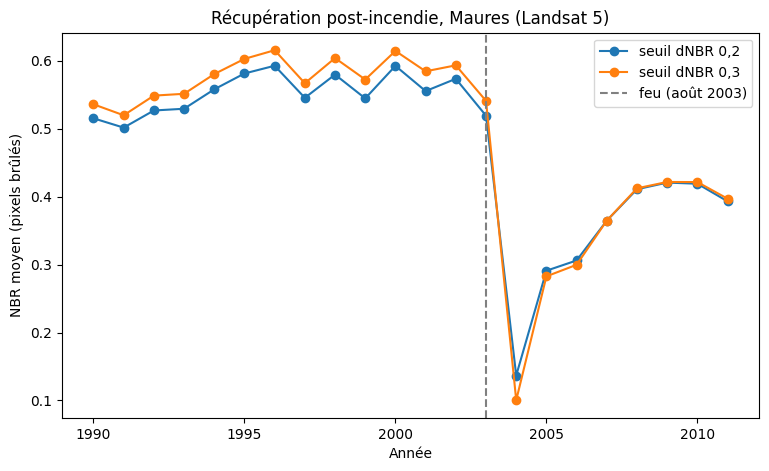

In [33]:
import matplotlib.pyplot as plt

# Calcul de df_03 car il n'avait pas encore été généré
df_03 = trajectoire_complete(0.3)

df_02 = df_02.sort_values("annee")
df_03 = df_03.sort_values("annee")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_02["annee"], df_02["NBR"], marker="o", label="seuil dNBR 0,2")
ax.plot(df_03["annee"], df_03["NBR"], marker="o", label="seuil dNBR 0,3")
ax.axvline(2003, color="grey", linestyle="--", label="feu (août 2003)")
ax.set_xlabel("Année")
ax.set_ylabel("NBR moyen (pixels brûlés)")
ax.set_title("Récupération post-incendie, Maures (Landsat 5)")
ax.legend()
plt.show()

In [34]:
for nom, df in [("0,2", df_02), ("0,3", df_03)]:
    base = df[df["annee"] <= 2002]["NBR"].mean()
    df["NBR_rel"] = df["NBR"] / base * 100
    print("seuil", nom, "base =", round(base, 3))
    print(df[df["annee"] >= 2003][["annee", "NBR_rel"]].round(1))

seuil 0,2 base = 0.554
    annee  NBR_rel
13   2003     93.8
14   2004     24.7
15   2005     52.6
16   2006     55.3
17   2007     65.9
18   2008     74.2
19   2009     76.0
20   2010     75.7
21   2011     71.0
seuil 0,3 base = 0.576
    annee  NBR_rel
13   2003     93.9
14   2004     17.4
15   2005     49.1
16   2006     52.0
17   2007     63.3
18   2008     71.6
19   2009     73.2
20   2010     73.1
21   2011     68.9


In [35]:
chute = nbr_ete(2010).subtract(nbr_ete(2011)).rename("chute")

m = geemap.Map(basemap="SATELLITE")
m.centerObject(zone, 11)
m.addLayer(chute.clip(zone), {"min": 0, "max": 0.3,
           "palette": ["white", "yellow", "red"]}, "Chute NBR 2010-2011")
m.addLayer(brule.selfMask().clip(zone), {"palette": ["blue"]}, "Pixels brûlés 2003", True, 0.4)
m.addLayer(zone, {"color": "cyan"}, "Zone A", True, 0.2)
m

Map(center=[43.29520668730594, 6.452976509242476], controls=(WidgetControl(options=['position', 'transparent_b…

In [36]:
def trajectoire_masque(masque, debut, fin):
    def comp(annee):
        annee = ee.Number(annee)
        img = (l5_nbr.filterDate(ee.Date.fromYMD(annee, 6, 1),
                                 ee.Date.fromYMD(annee, 9, 30))
               .select("NBR").median().updateMask(masque))
        val = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=zone,
                               scale=30, bestEffort=True, maxPixels=1e9).get("NBR")
        return ee.Feature(None, {"annee": annee, "NBR": val})
    res = ee.FeatureCollection(ee.List.sequence(debut, fin).map(comp)).getInfo()
    return [f["properties"] for f in res["features"]]

temoin = dnbr.lt(0.05)   # pixels sans baisse notable, seuil provisoire de ma part

lignes = []
for d in range(1990, 2012, 5):
    lignes += trajectoire_masque(temoin, d, min(d + 4, 2011))
    time.sleep(5)
df_temoin = pd.DataFrame(lignes).sort_values("annee")
print(df_temoin)

         NBR  annee
0   0.541380   1990
1   0.544641   1991
2   0.543814   1992
3   0.563870   1993
4   0.574258   1994
5   0.599791   1995
6   0.607418   1996
7   0.568749   1997
8   0.599723   1998
9   0.578520   1999
10  0.600743   2000
11  0.585450   2001
12  0.571260   2002
13  0.572470   2003
14  0.583446   2004
15  0.538609   2005
16  0.537190   2006
17  0.538986   2007
18  0.564278   2008
19  0.531904   2009
20  0.583675   2010
21  0.570092   2011
